In [21]:
import os
# Must be set before numpy is imported. n=128 matrices are too small for
# multithreaded BLAS: one thread is ~18x faster, and lets the cells below run in parallel.
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.dpi":300,
})


# Find harmonic.py in this folder or its parent
folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent
sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator

In [22]:
# simulate() lives in simulation.py so parallel workers can import it (needed on Windows)
from simulation import simulate, transition_prob

In [23]:
n = 128
L = 12
tmax = 200

# First excited state, using the same grid as the simulation
ho = HarmonicOscillator(boundary=(-L, L), n=n)
_, basis = ho.eigenstates()
phi1 = basis[:, 1]

alpha = 0.02

## Energy Correction

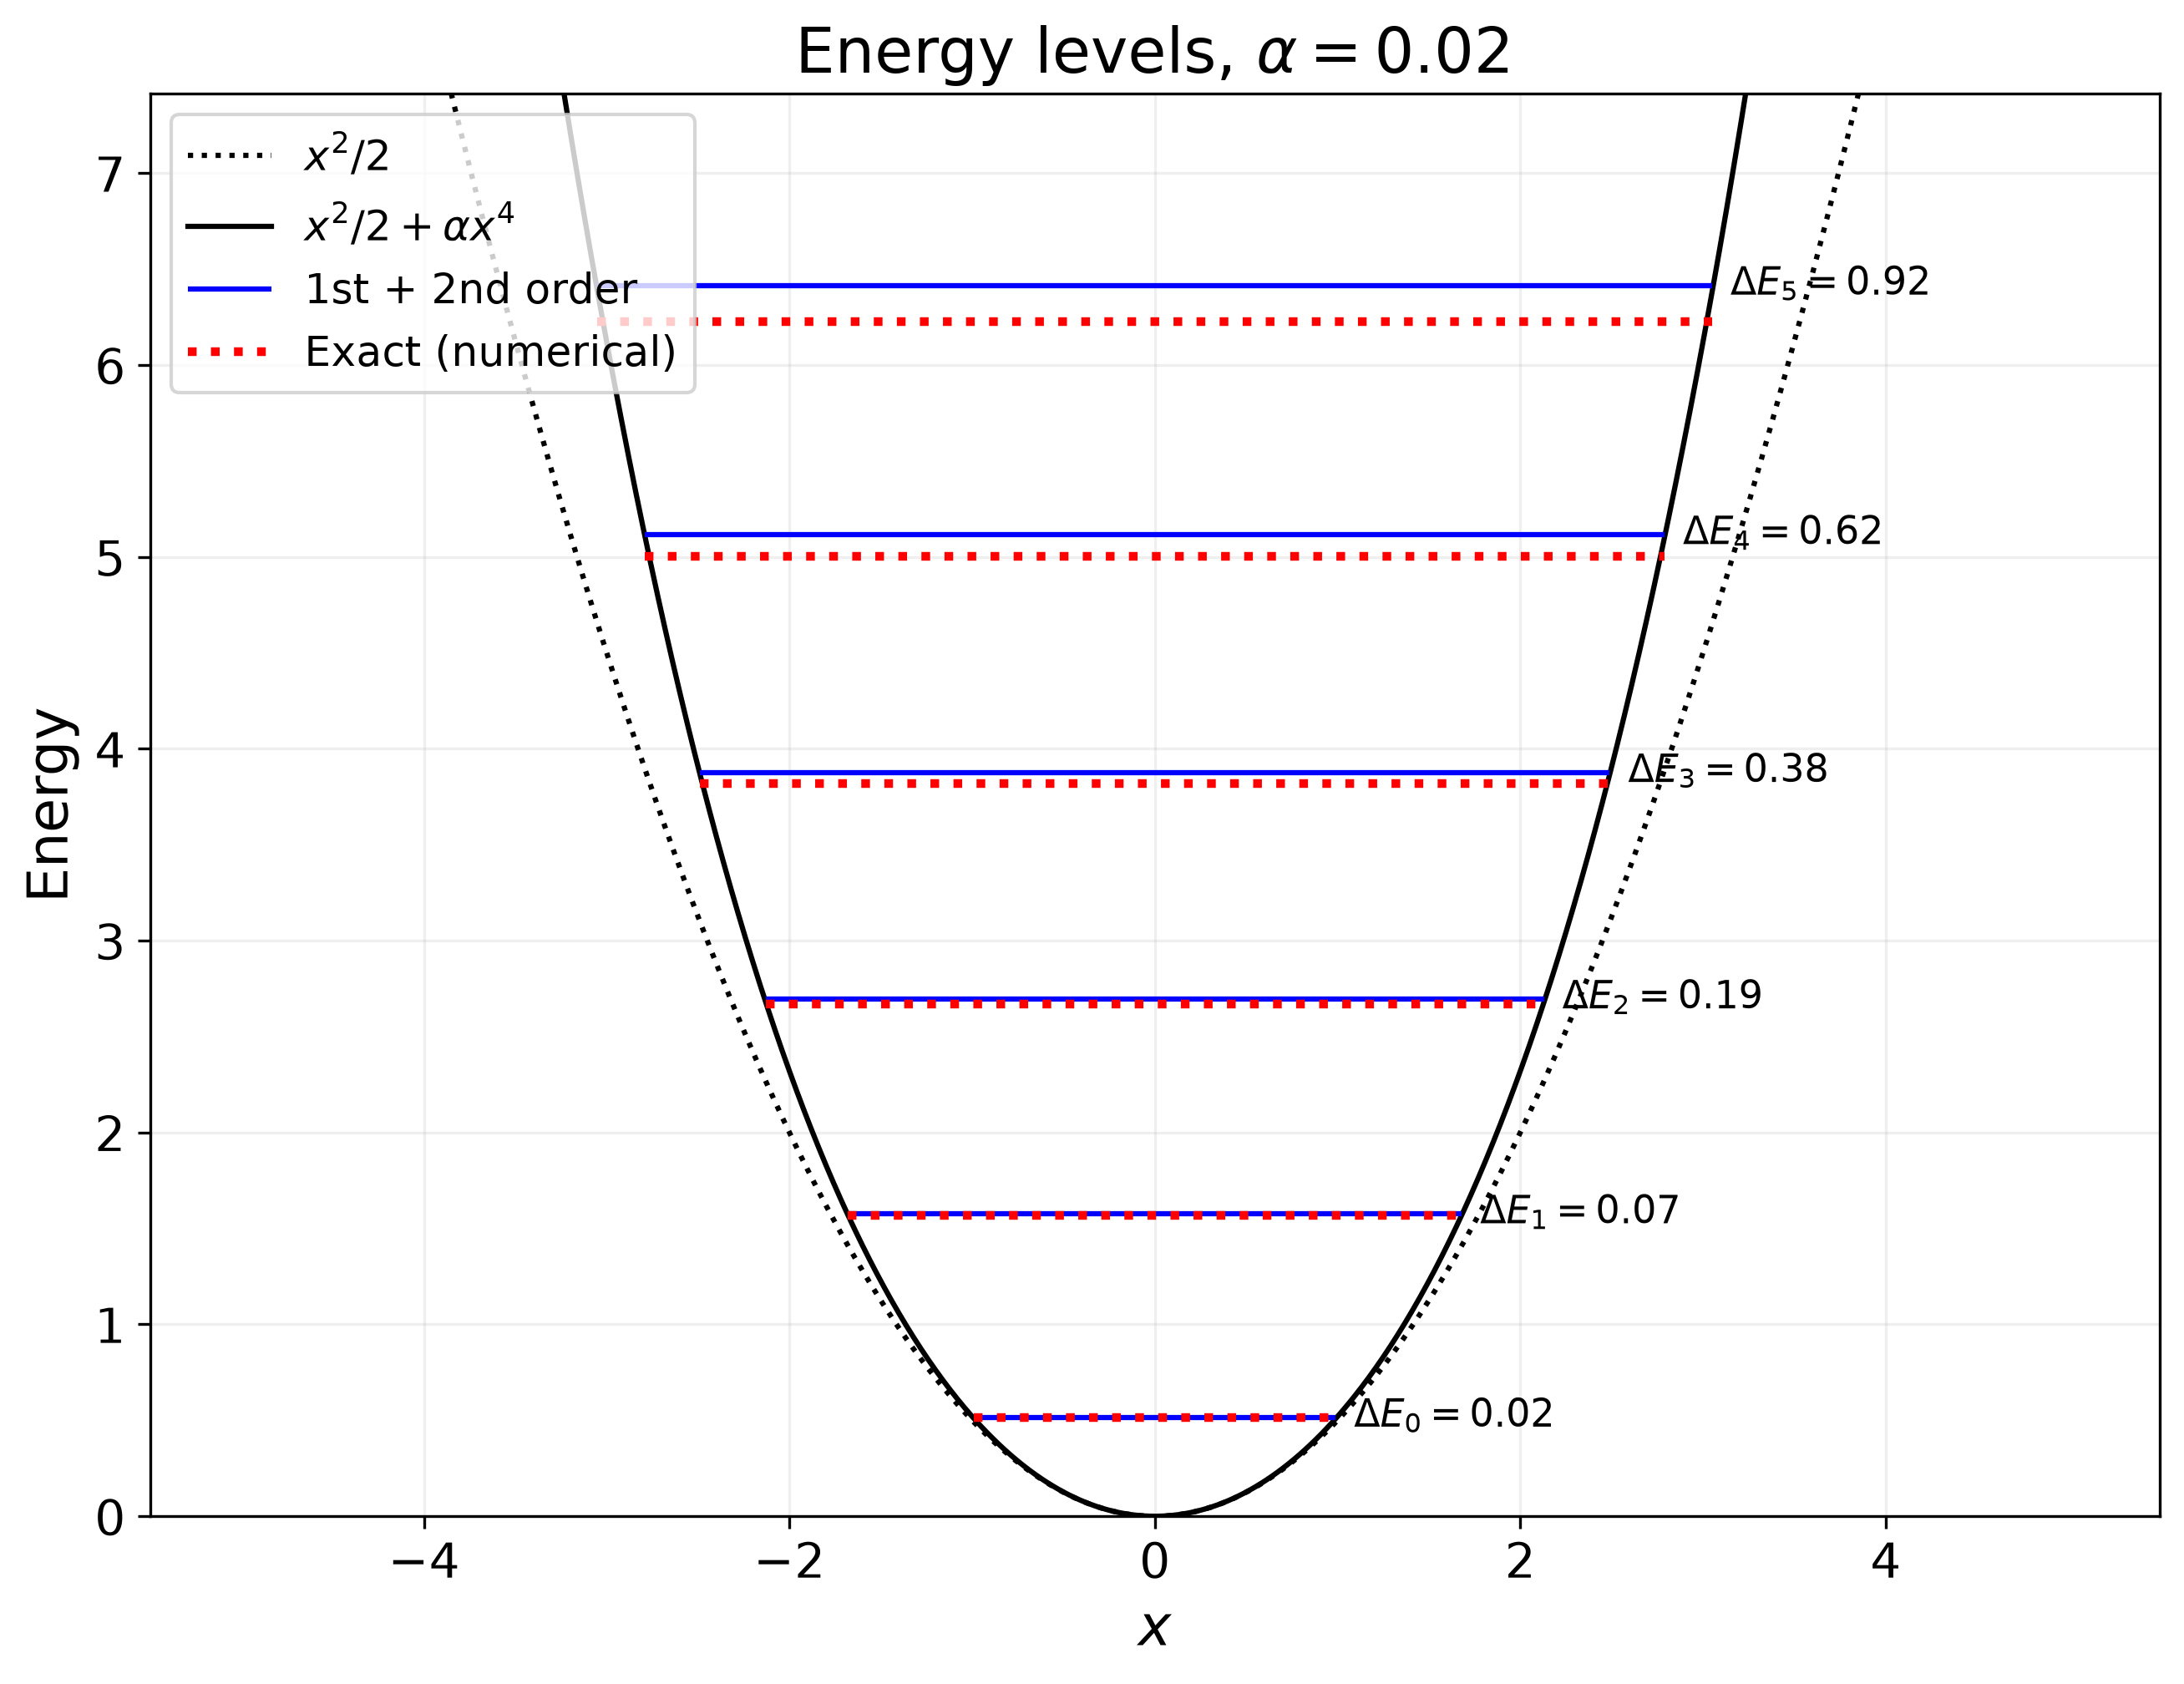

In [ ]:
from analytic import _x4

# H = p^2/2 + x^2/2 + alpha x^4
levels = np.arange(0, 6)
x = np.linspace(-4, 4, 801)
V = x**2 / 2 + alpha * x**4

E0 = levels + 0.5
E1 = alpha * _x4(levels, levels)
E_pt = E0 + E1

# Exact levels: diagonalise H on the simulation grid
F = np.fft.fft(np.eye(n), axis=0)
H = np.linalg.inv(F) @ np.diag(ho.pi()**2 / 2) @ F + np.diag(ho.xi()**2 / 2 + alpha * ho.xi()**4)
E_exact = np.linalg.eigvalsh(H)[levels]

plt.figure(figsize=(9, 7))
plt.plot(x, x**2 / 2, "k:", label=r"$x^2/2$")
plt.plot(x, V, "k-", label=r"$x^2/2 + \alpha x^4$")

for m, (e0, e, ex) in enumerate(zip(E0, E_pt, E_exact)):
    inside = x[V <= e]  # classically allowed region
    first = m == 0
    plt.hlines(e, inside.min(), inside.max(), colors="b",
               label="1st + 2nd order" if first else None)
    plt.hlines(ex, inside.min(), inside.max(), colors="r", linestyles=":", linewidth=2.5,
               label="Exact (numerical)" if first else None)
    plt.text(inside.max() + 0.1, e, rf"$\Delta E_{m}={e - e0:.2f}$", va="center", fontsize=11)

plt.xlabel(r"$x$")
plt.ylabel("Energy")
plt.title(rf"Energy levels, $\alpha={alpha}$")
plt.ylim(0, max(E_pt.max(), E_exact.max()) + 1)
plt.xlim(-5.5, 5.5)
plt.legend(loc="upper left", fontsize=12)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

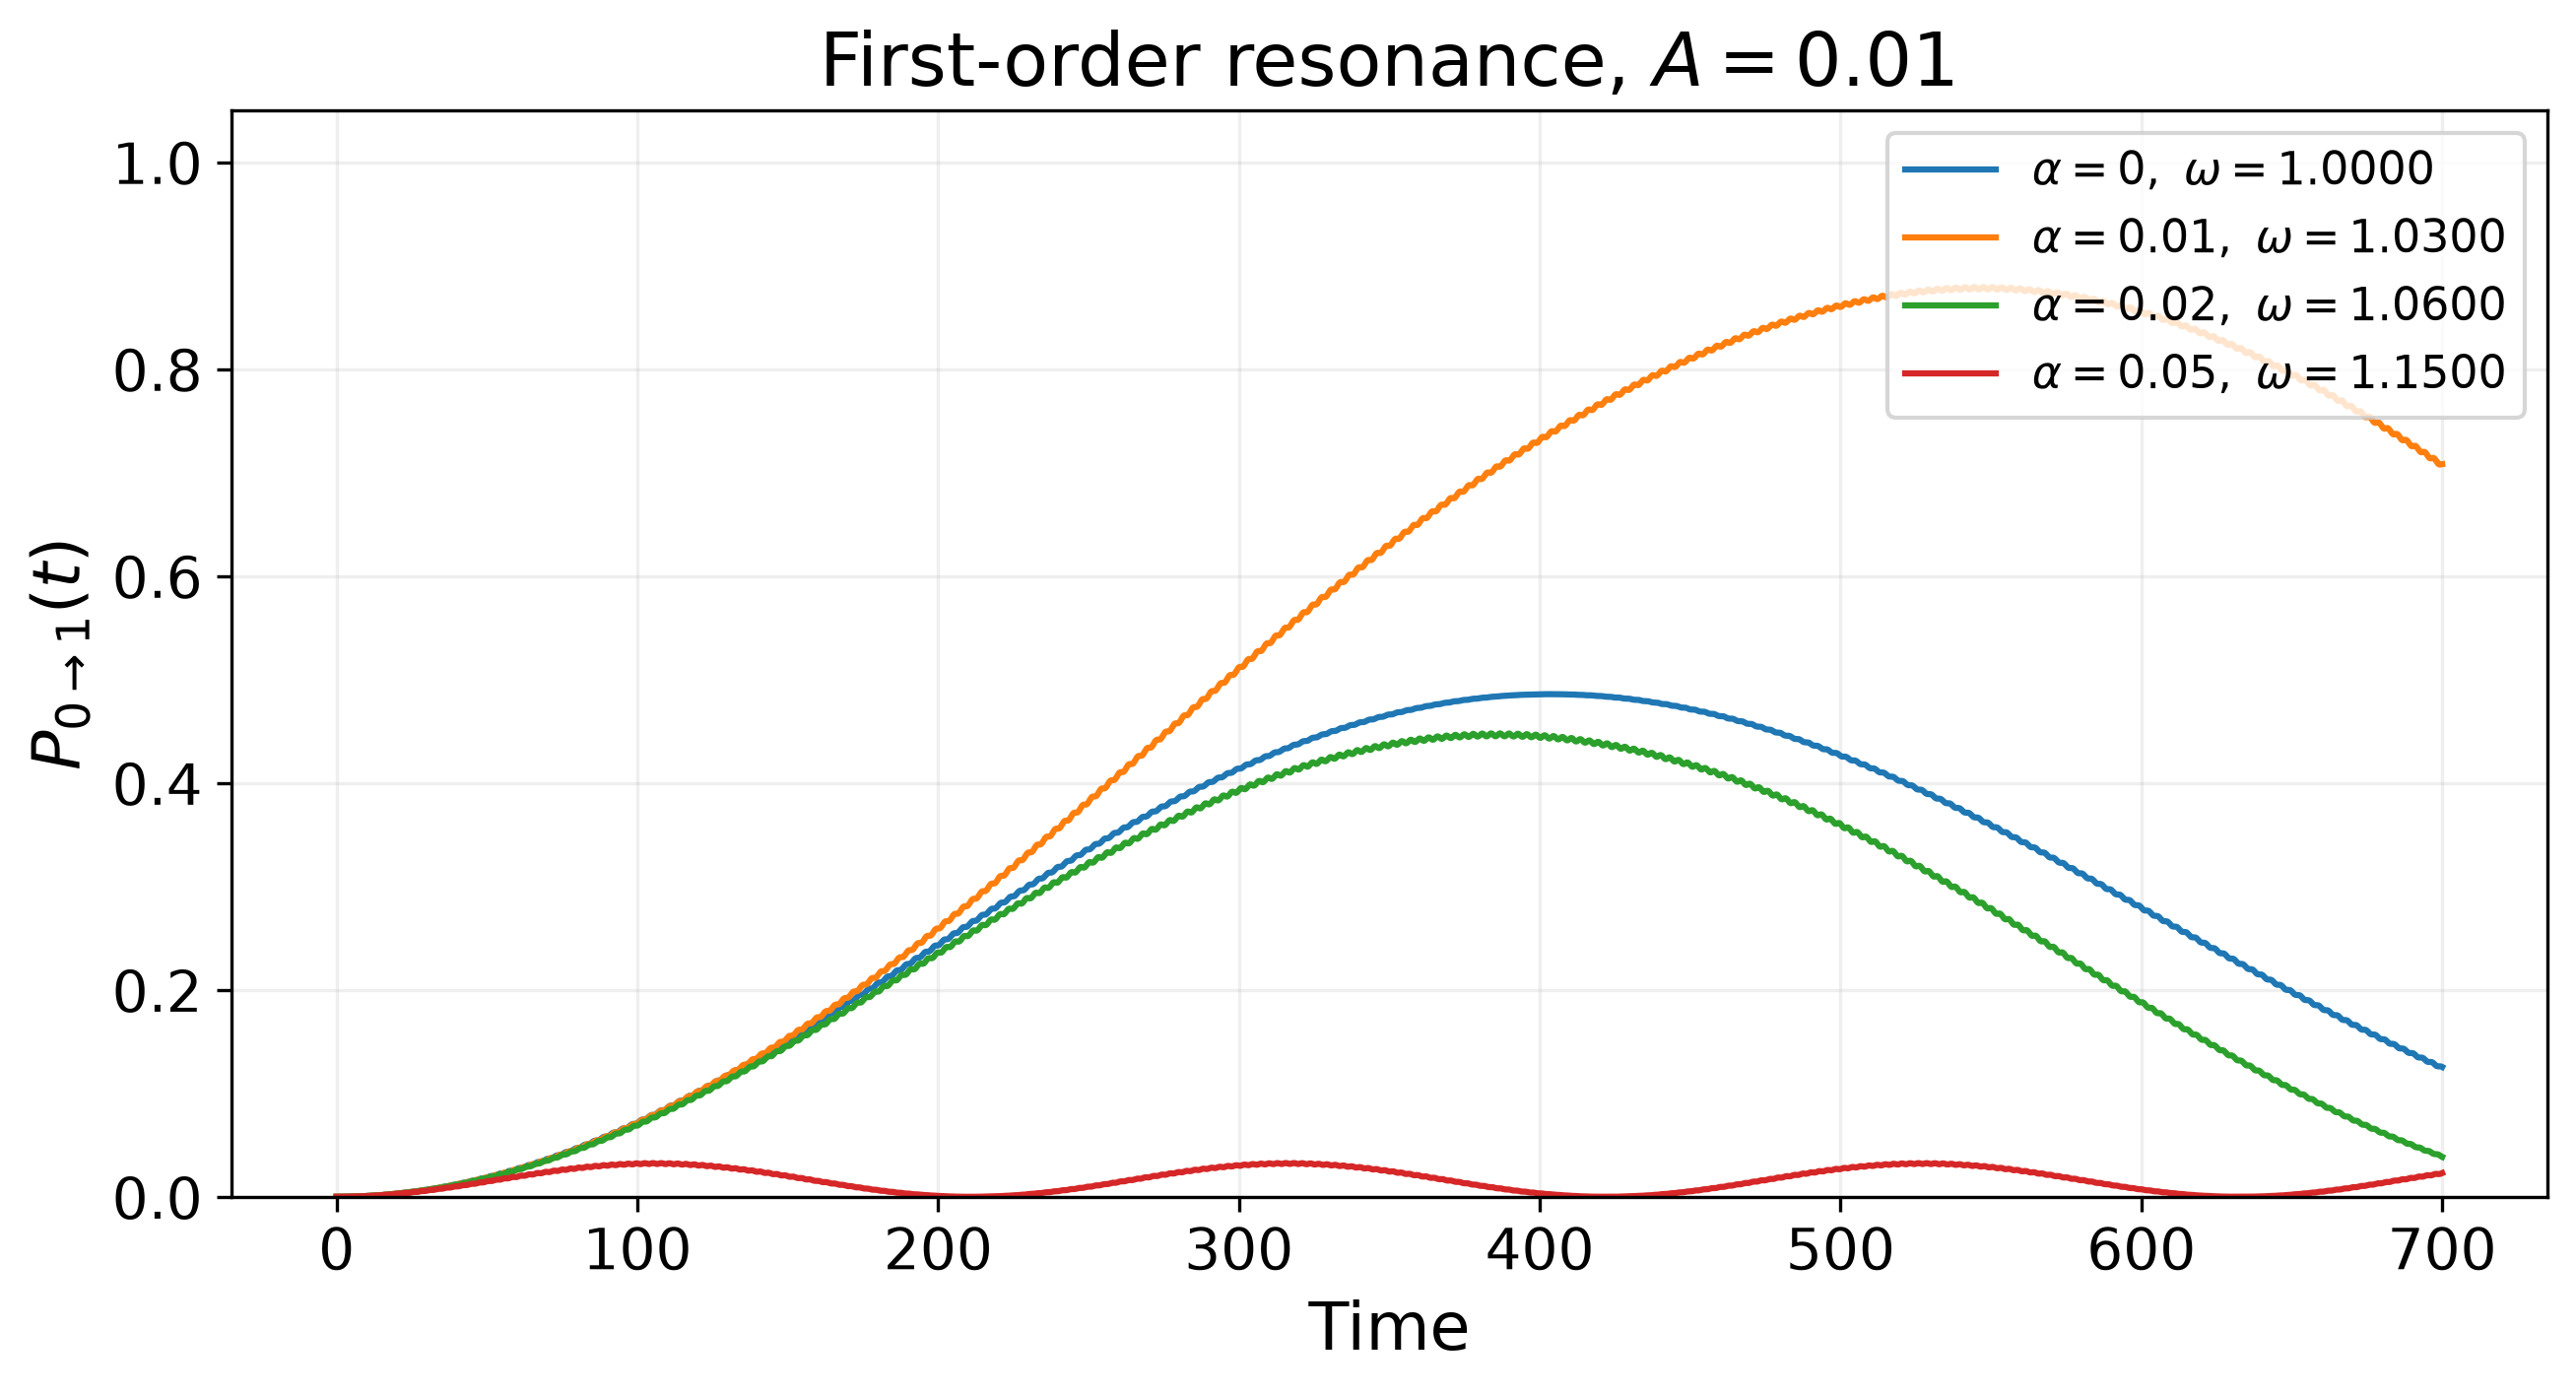

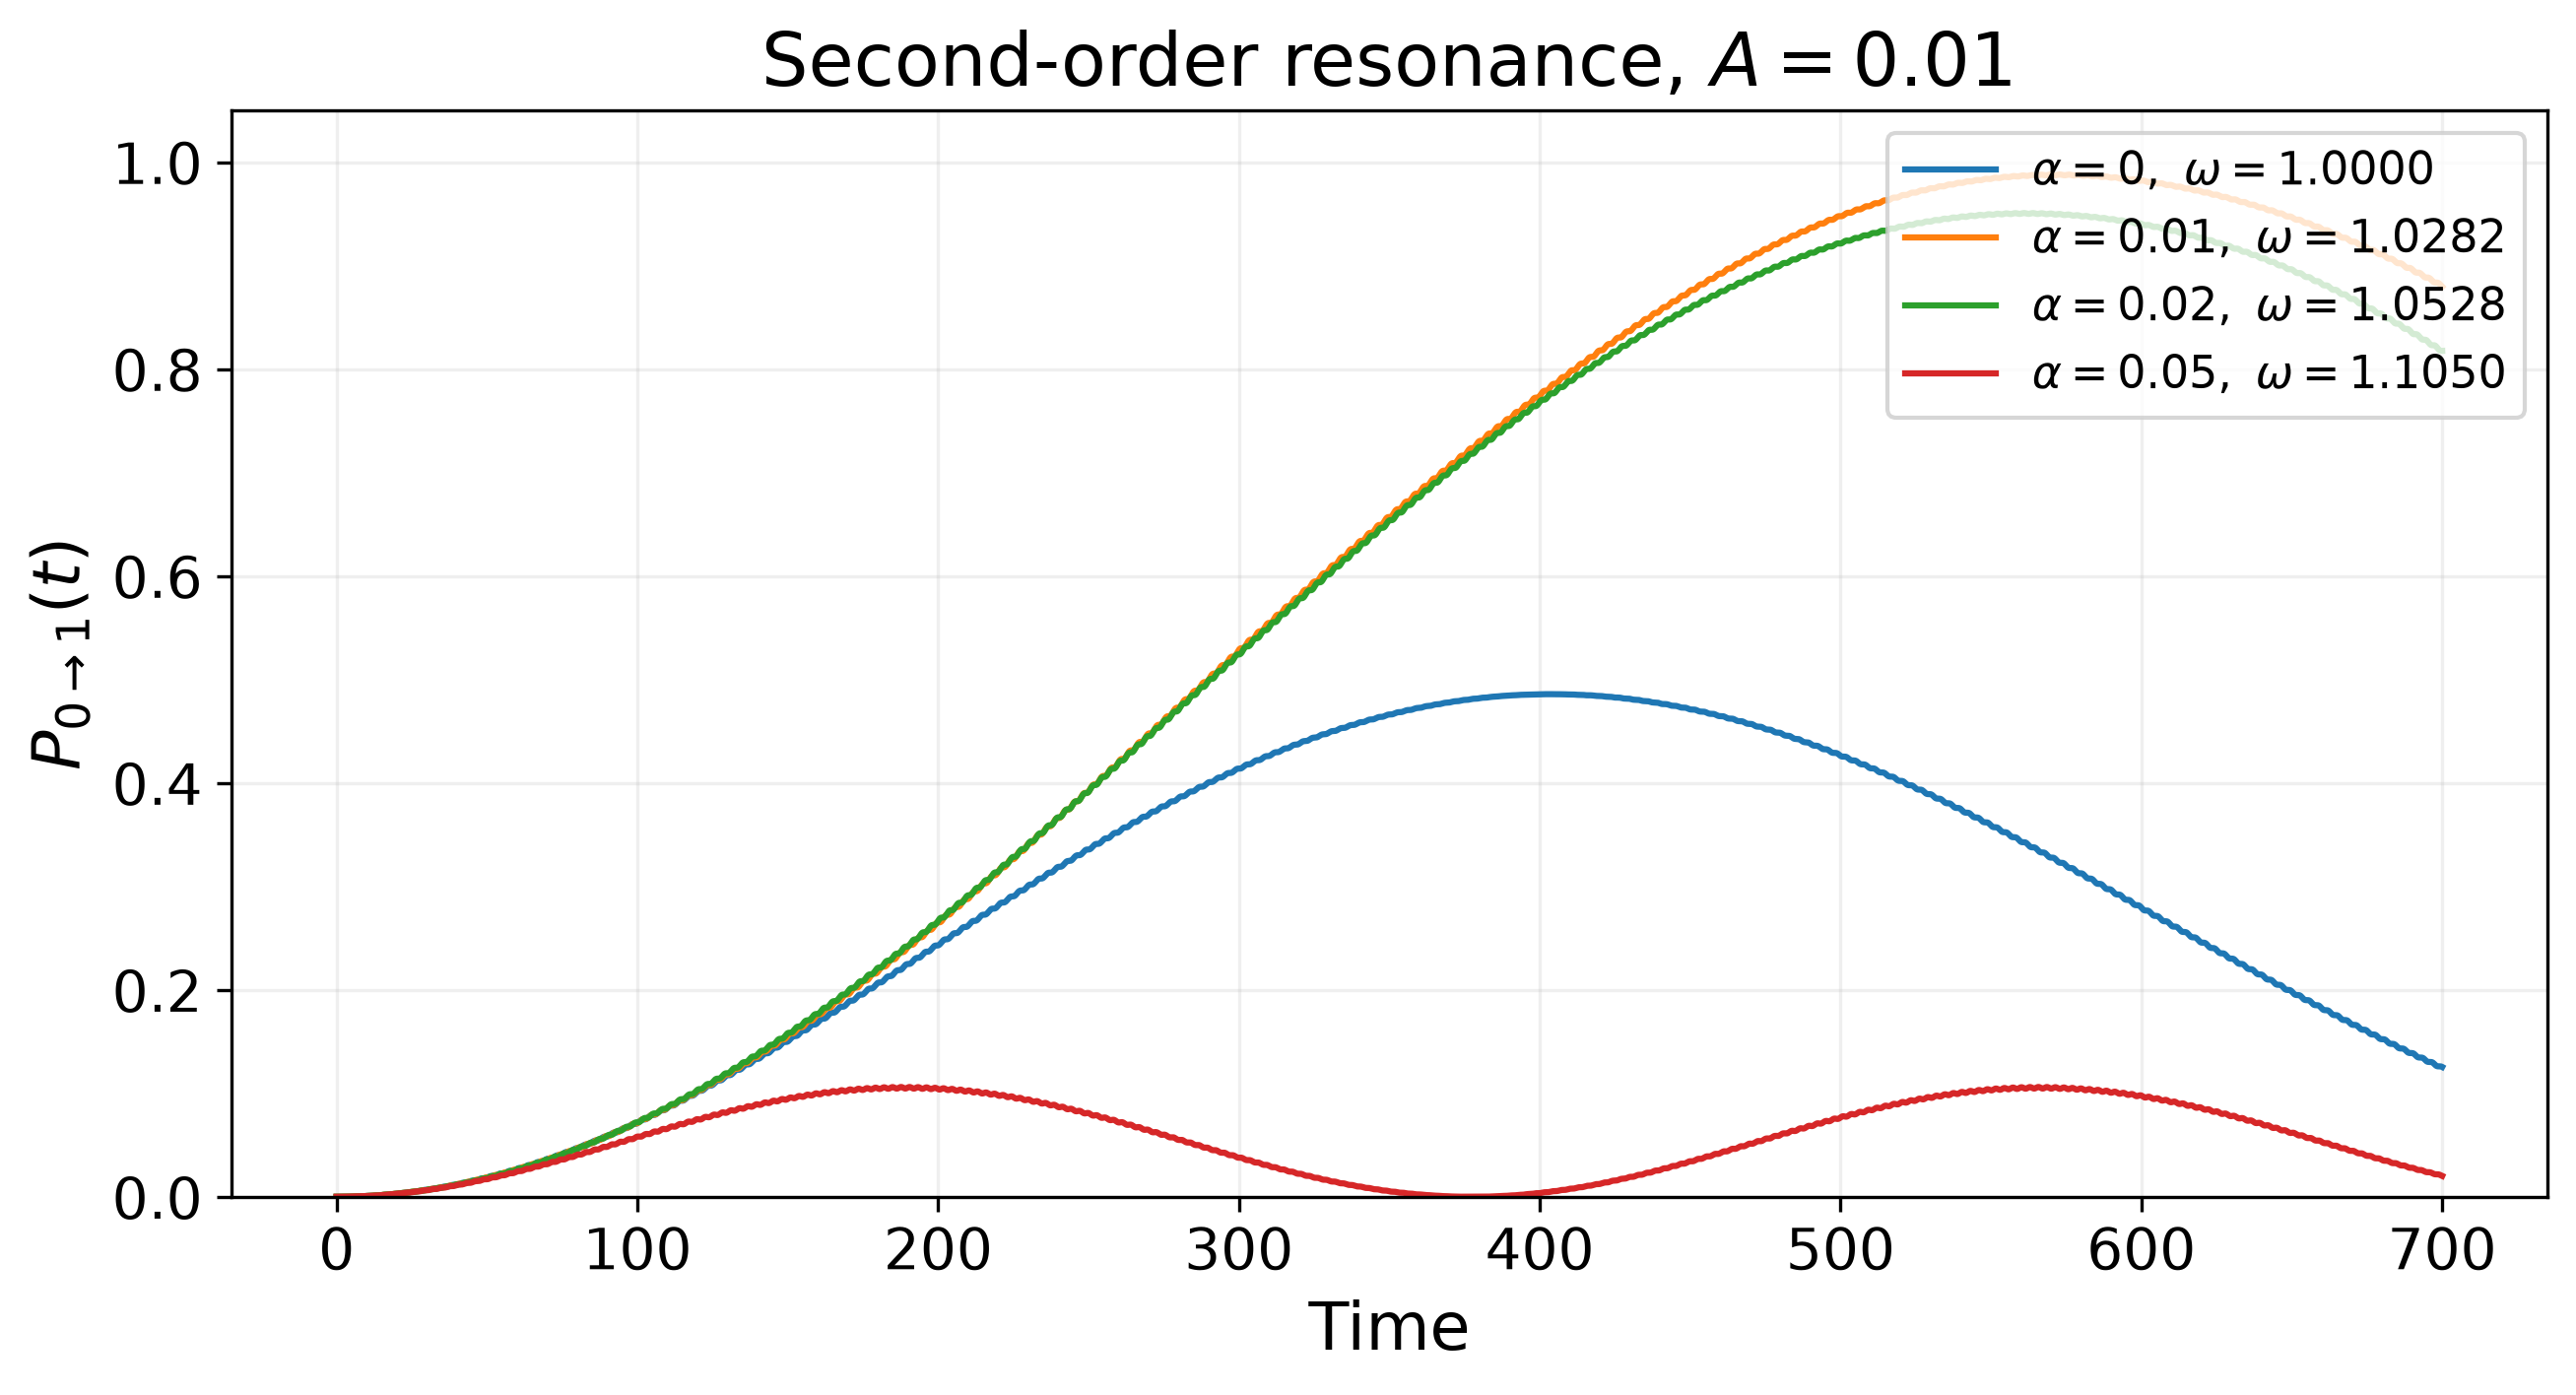

In [ ]:
from concurrent.futures import ProcessPoolExecutor
from analytic import _x4

alphas = [0, 0.01, 0.02, 0.05]
A = 0.01
tmax = 700 

def E2(m):
    return sum(_x4(k, m)**2 / (m - k) for k in range(m + 5) if k != m)

omegas = {
    "First": {a: 1 + a * (_x4(1, 1) - _x4(0, 0)) for a in alphas},
    "Second": {a: 1 + a * (_x4(1, 1) - _x4(0, 0)) + a**2 * (E2(1) - E2(0)) for a in alphas},
}


jobs = {(a, w[a]) for w in omegas.values() for a in alphas}
with ProcessPoolExecutor() as pool:
    futures = {job: pool.submit(transition_prob, A, job[1], tmax, n=n, L=L, alpha=job[0]) for job in jobs}
    runs = {job: f.result() for job, f in futures.items()}


for order, w in omegas.items():
    fig, ax = plt.subplots(figsize=(9, 5))
    for a in alphas:
        t, P1 = runs[(a, w[a])]
        ax.plot(t, P1, label=rf"$\alpha={a},\ \omega={w[a]:.4f}$")

    ax.set_title(rf"{order}-order resonance, $A={A}$")
    ax.set_xlabel("Time")
    ax.set_ylabel(r"$P_{0\to1}(t)$")
    ax.set_ylim(0, 1.05)
    ax.legend(loc="upper right", fontsize=11)
    ax.grid(alpha=0.2)
    fig.tight_layout()

plt.show()

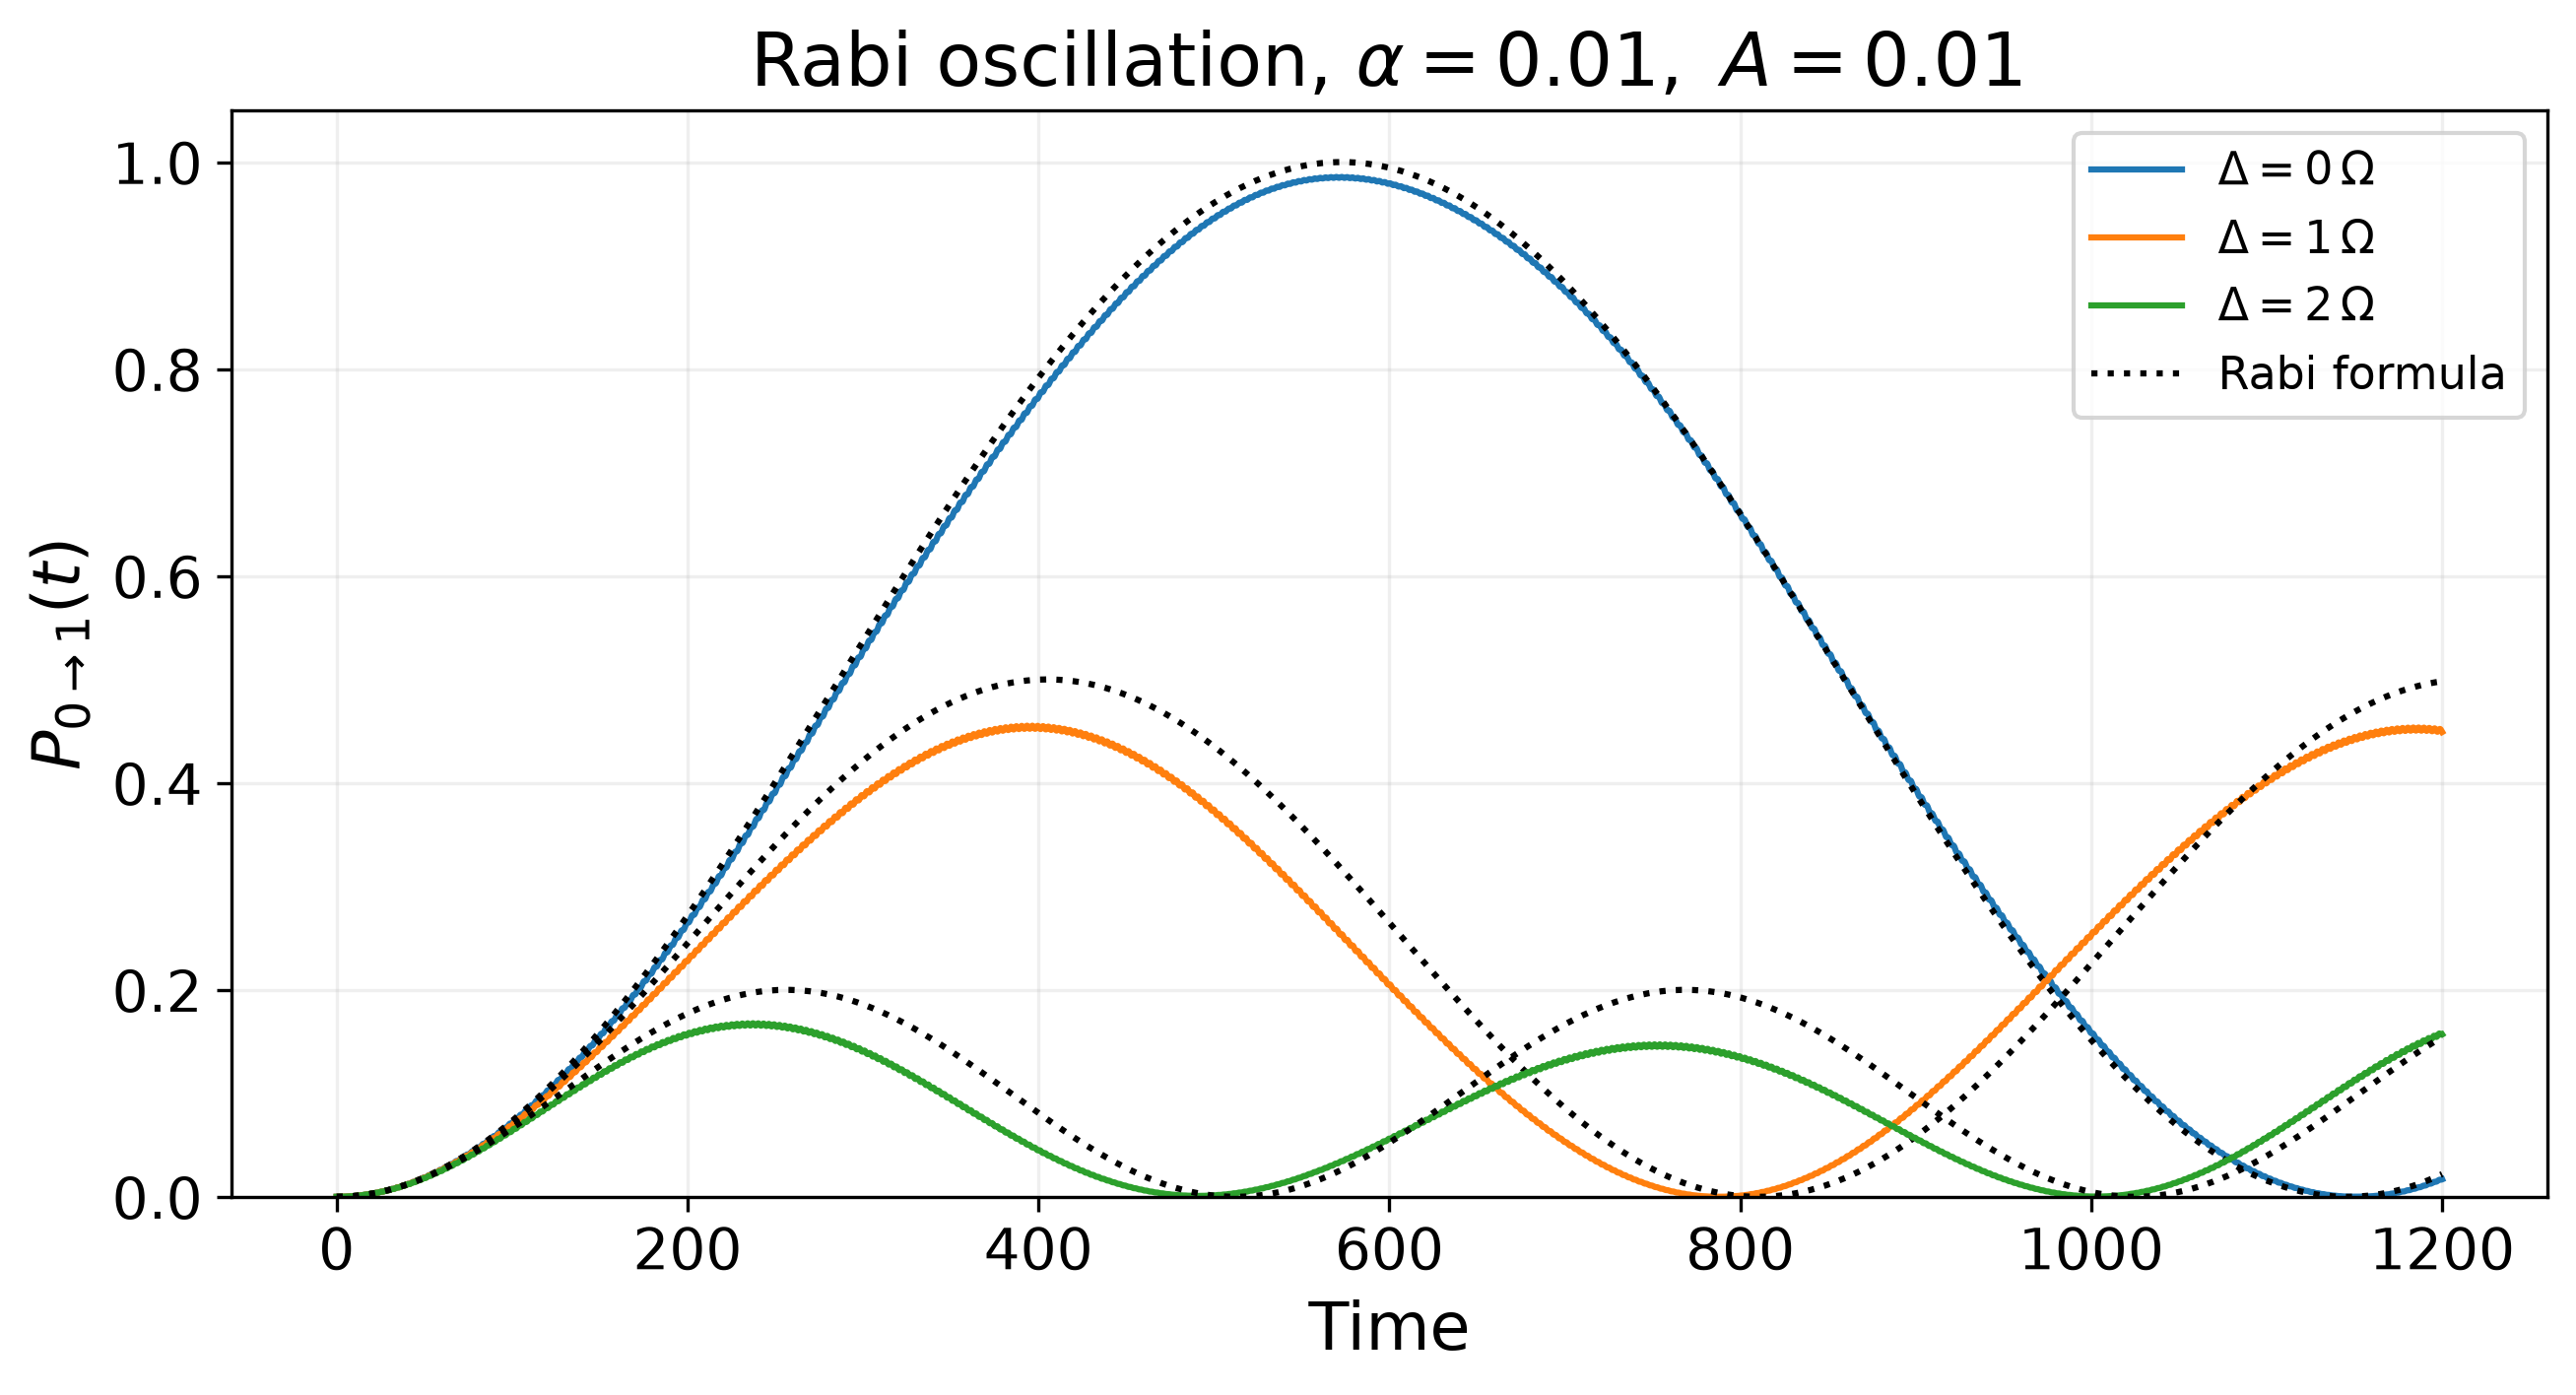

In [ ]:
a = 0.01
tmax_rabi = 1200  
ho_a = HarmonicOscillator(boundary=(-L, L), n=n, alpha=a)
E_a, basis_a = ho_a.eigenstates()
w10 = E_a[1] - E_a[0]
V10 = abs(basis_a[:, 1].conj() @ (np.sin(ho_a.xi()) * basis_a[:, 0]))

def rabi(t, A, Delta):
    Omega = A * V10
    Omega_R = np.sqrt(Omega**2 + Delta**2)
    return (Omega / Omega_R)**2 * np.sin(Omega_R * t / 2)**2

A0 = 0.01
detunings = [0, 1, 2] 

with ProcessPoolExecutor() as pool:
    futures = {k: pool.submit(transition_prob, A0, w10 + k * A0 * V10, tmax_rabi, n=n, L=L, alpha=a)
               for k in detunings}
    rabi_runs = {k: f.result() for k, f in futures.items()}

fig, ax = plt.subplots(figsize=(9, 5))

for i, k in enumerate(detunings):
    t, P1 = rabi_runs[k]
    ax.plot(t, P1, color=f"C{i}", label=rf"$\Delta={k}\,\Omega$")
    ax.plot(t, rabi(t, A0, k * A0 * V10), "k:", linewidth=1.5, label="Rabi formula" if i == len(detunings) - 1 else None)

ax.set_title(rf"Rabi oscillation, $\alpha={a},\ A={A0}$")
ax.set_xlabel("Time")
ax.set_ylabel(r"$P_{0\to1}(t)$")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right", fontsize=11)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()